In [ ]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from sklearn.linear_model import LinearRegression

from experiments_utils import RESULTS_DIR

# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

/home/prajwal/github-repos/knnsur/src/__init__.py:18: UserWarning: CuPy not available; GPU acceleration will be disabled.
  warnings.warn(msg)


In [ ]:
ICS26_DIR = RESULTS_DIR / "ics26"
for d in ICS26_DIR.iterdir():
    print(d.name)

ics_anisotropic_gaussian
ics_anisotropic_quadratic
ics_anisotropic_quadratic_runtime_scalability
ics_rosenbrock_runtime_scalability
ics_anisotropic_quadratic_no_hess
ics_anisotropic_quadratic_no_hess_no_grad
ics_anisotropic_gaussian_no_hess
ics_anisotropic_gaussian_no_hess_no_grad
ics_rosenbrock_no_hess
ics_rosenbrock_no_hess_no_grad
ics_lorenz_finaltime0.1_outputvar0_forcing1
ics_lorenz_finaltime0.05_outputvar0_forcing1
ics_rosenbrock_runtime_scalability_n0


In [ ]:
def plot_error_with_log_log_fit(
    df,
    error_col1,
    error_col2,
    title1,
    title2,
    error_metric_col="ERROR_METRIC",
    skip_first_n=0,
    dim_col="dim",
):
    # drop rows where error_col1 or error_col2 is  or zero
    df = df[(df[error_col1] > 0) & (df[error_col2] > 0)]
    plt.figure(figsize=(16, 6))
    plt.subplot(1, 2, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col1,
        hue=dim_col,
        style=error_metric_col,
        marker="o",
        palette=PALETTE,
    )
    for dim in df[dim_col].unique():
        for e in df[error_metric_col].unique():
            subset = df[(df[dim_col] == dim) & (df[error_metric_col] == e)]
            if len(subset) <= 1:
                continue
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col1].values)
            if skip_first_n > 0:
                X = X[skip_first_n:]
                y = y[skip_first_n:]
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (E={e}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
            plt.plot(
                np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label
            )
        plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col1.replace("_", " ").title())
    plt.title(title1)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 2, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col2,
        hue=dim_col,
        style=error_metric_col,
        marker="o",
        palette=PALETTE,
    )
    for dim in df[dim_col].unique():
        for e in df[error_metric_col].unique():
            subset = df[(df[dim_col] == dim) & (df[error_metric_col] == e)]
            if len(subset) <= 1:
                continue
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col2].values)
            if skip_first_n > 0:
                X = X[skip_first_n:]
                y = y[skip_first_n:]
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (E={e}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col2.replace("_", " ").title())
    plt.title(title2)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()


def plot_percentage_metrics(df, dim_col="dim"):
    plt.figure(figsize=(24, 7))
    plt.subplot(1, 3, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_out",
        hue=dim_col,
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ out (perct_out)")
    plt.title(r"$\%$ out vs Number of Cluster")
    plt.ylim(0, 100)
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 3, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_in_good",
        hue=dim_col,
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ in-Good (perct_in_good)")
    plt.ylim(0, 100)
    plt.title(r"$\%$ in-Good vs Number of Cluster")
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 3, 3)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_in_bad",
        hue=dim_col,
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ in-Bad (perct_in_bad)")
    plt.ylim(0, 100)
    plt.title(r"$\%$ in-Bad vs Number of Cluster")
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()

# Problems

In [ ]:
prob_dir = ICS26_DIR / "ics_rosenbrock_runtime_scalability"
csv_path = prob_dir / "summary.csv"

df_problem = pd.read_csv(csv_path)
df_problem = df_problem.dropna(subset=["n_clusters"])

if "n_min_per_cluster" in prob_dir.name:
    dim_col = "dim_n_min_per_cluster"
    df_problem[dim_col] = (
        df_problem["dim"].astype(str)
        + "D_"
        + df_problem["N_MIN_PER_CLUSTER"].astype(str)
    )
else:
    dim_col = "dim"

In [ ]:
# _temp = df_problem[["dim", "n_clusters", "predict_time_sec"]]
# _temp.to_clipboard(index=False)

In [ ]:
df_problem.columns

Index(['problem_name', 'problem_tag', 'tol', 'dim', 'f_dim', 'n_train',
       'n_test', 'n_clusters', 'in_ptwise_max_rel_error_linf',
       'in_ptwise_median_rel_error_linf', 'in_l2_relative_error',
       'in_l2_abs_error', 'out_l2_relative_error', 'out_l2_abs_error',
       'out_ptwise_max_rel_error_linf', 'out_ptwise_median_rel_error_linf',
       'all_ptwise_max_rel_error_linf', 'all_ptwise_median_rel_error_linf',
       'all_l2_relative_error', 'all_l2_abs_error', 'n_out', 'perct_out',
       'n_in', 'n_in_good', 'perct_in_good', 'n_in_bad', 'perct_in_bad',
       'train_time_sec', 'predict_time_sec', 'error_tag', 'num_levels',
       'num_generated_pts', 'total_f_evals', 'N_INIT_CLUSTERS',
       'N_MIN_PER_CLUSTER', 'K_NEIGHBOURS', 'USE_HESSIAN_INFORMED_SPLIT',
       'IGNORE_GRADIENT', 'ERROR_METRIC', 'BATCH_SIZE', 'PROFILE_TIMING'],
      dtype='object')

In [ ]:
rename_cols = {
    "dim": "d",
    "tol": "rtol",
    "total_f_evals": "N",
    "n_clusters": "Nc",
    "n_train": "N0",
    "n_test": "N_test",
    "train_time_sec": "Train Time (sec)",
    "predict_time_sec": "Predict Time (sec)",
    "all_l2_relative_error": "e",
}
_temp = df_problem.rename(columns=rename_cols)[rename_cols.values()]
display(_temp)
_temp.to_clipboard(index=False)

,d,rtol,N,Nc,N0,N_test,Train Time (sec),Predict Time (sec),e
0,5,1.000,185740,93,185646,46411,0.521638,0.008346,0.392816
1,5,0.500,278583,464,185646,46411,1.201558,0.008445,0.306701
2,5,0.200,2696160,7208,185646,46411,1.934152,0.011714,0.096687
3,5,0.100,11230938,30110,185646,46411,2.685587,0.013441,0.057319
4,5,0.050,37477083,100475,185646,46411,3.813388,0.025121,0.042083
5,5,0.020,150010437,402173,185646,46411,8.753417,0.066587,0.032096
6,5,0.010,396729795,1063619,185646,46411,16.521395,0.158568,0.027748
7,5,0.005,1025629802,2749678,185646,46411,38.454205,0.405165,0.024244


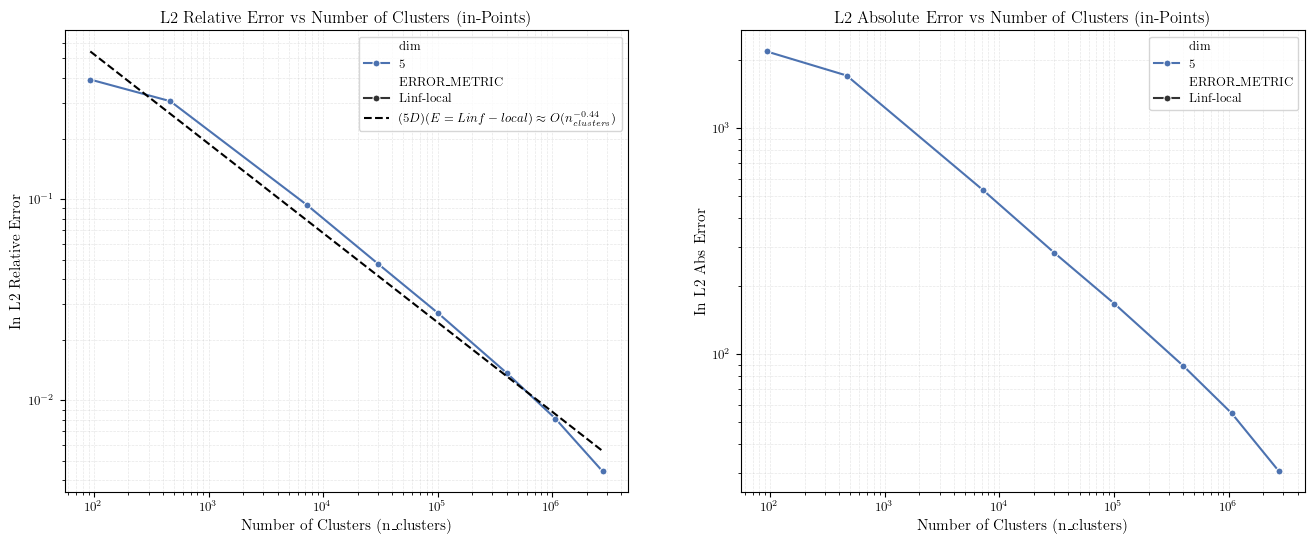

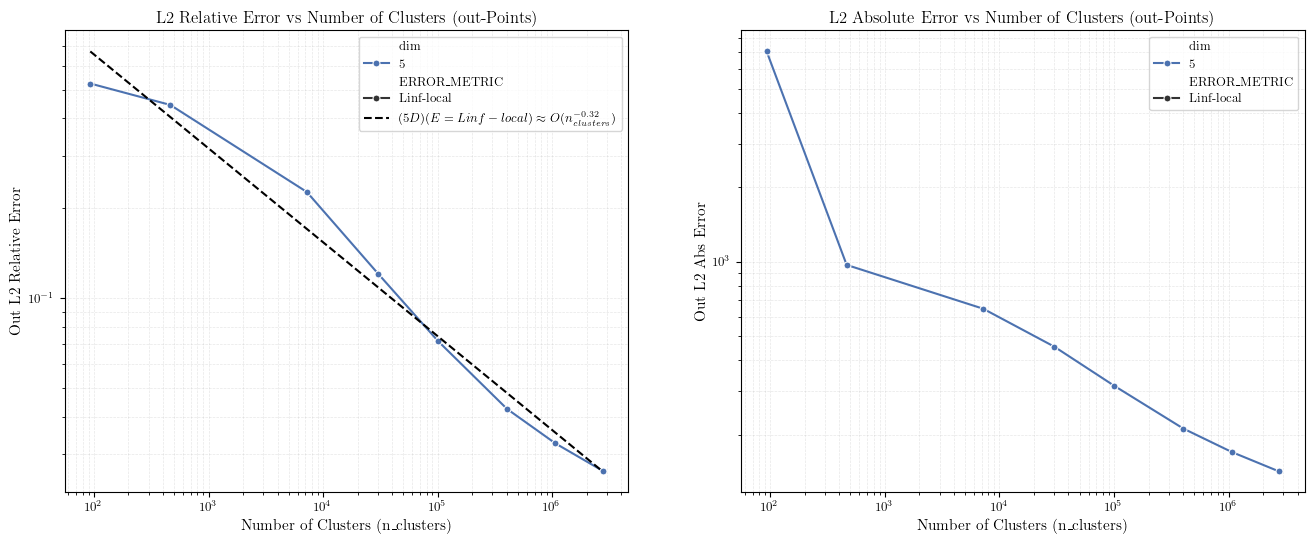

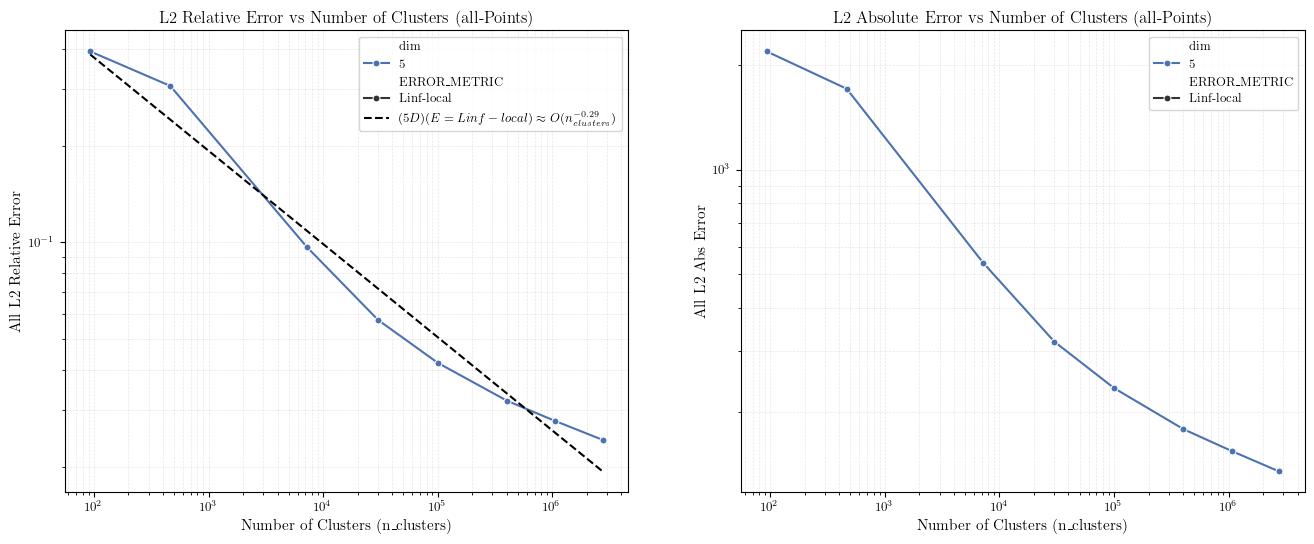

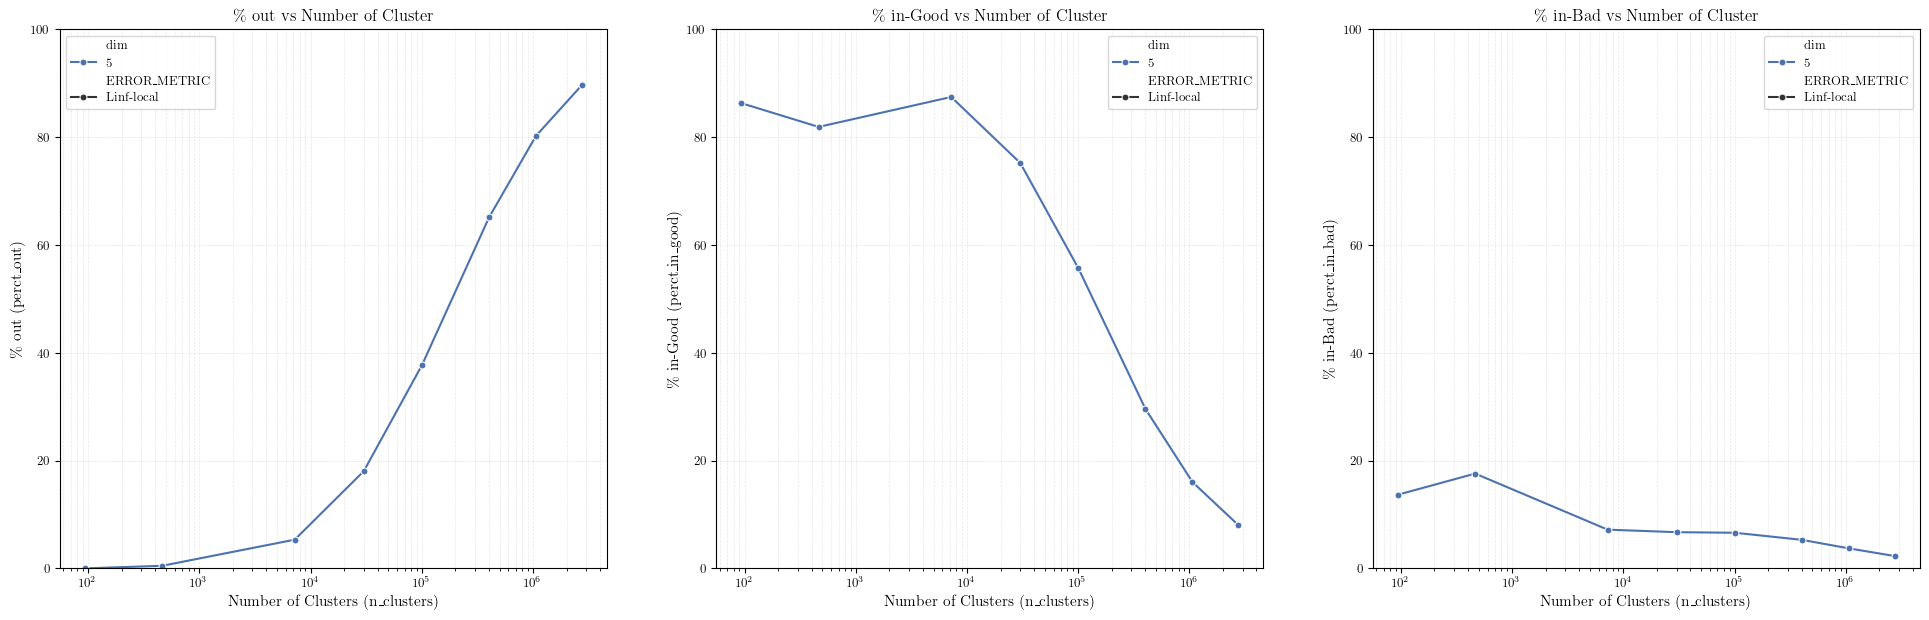

In [ ]:
if "hessian_estimation" in prob_dir.name:
    plot_error_with_log_log_fit(
        df_problem,
        "l2_rel_error",
        "l2_abs_error",
        "L2 Relative Error vs Number of Clusters",
        "L2 Absolute Error vs Number of Clusters",
        error_metric_col="metric",
        skip_first_n=1,
    )
else:
    plot_error_with_log_log_fit(
        df_problem,
        "in_l2_relative_error",
        "in_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (in-Points)",
        "L2 Absolute Error vs Number of Clusters (in-Points)",
        dim_col=dim_col,
    )
    plot_error_with_log_log_fit(
        df_problem,
        "out_l2_relative_error",
        "out_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (out-Points)",
        "L2 Absolute Error vs Number of Clusters (out-Points)",
        dim_col=dim_col,
    )
    plot_error_with_log_log_fit(
        df_problem,
        "all_l2_relative_error",
        "all_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (all-Points)",
        "L2 Absolute Error vs Number of Clusters (all-Points)",
        dim_col=dim_col,
    )
    plot_percentage_metrics(df_problem, dim_col=dim_col)

In [ ]:
def get_renamed_df(df):
    rename_cols = {
        "dim": "D",
        "tol": "r_tol",
        "total_f_evals": "N",
        "n_clusters": "N_c",
        "perct_out": "p_o",
        "in_l2_relative_error": "e_in",
        "all_l2_relative_error": "e",
        "USE_HESSIAN_INFORMED_SPLIT": "Use Hessian",
        "IGNORE_GRADIENT": "Ignore Grad",
        # "perct_in_good": "% In-Good",
        # "perct_in_bad": "% In-Bad",
        # "in_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (In)",
        # "in_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (In)",
        # "out_l2_relative_error": "L2 Rel Err (Out)",
        # "in_l2_abs_error": "L2 Abs Err (In)",
        # "out_l2_abs_error": "L2 Abs Err (Out)",
        # "out_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (Out)",
        # "out_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (Out)",
        # "n_out": "N Out",
        # "ERROR_METRIC": "Error Metric",
        # "all_l2_abs_error": "L2 Abs Err (All)",
        # "all_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (All)",
        # "all_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (All)",
        # "N_INIT_CLUSTERS": "Init Clusters",
        # "N_MIN_PER_CLUSTER": "Min Per Cluster",
        # "n_train": "N Train",
        # "n_test": "N Test",
        # "num_generated_pts": "N Generated Pts",
    }
    df_renamed = df.rename(columns=rename_cols)[list(rename_cols.values())]
    return df_renamed


# if "hessian_estimation" in prob_dir.name:
display(get_renamed_df(df_problem))
get_renamed_df(df_problem).to_clipboard(index=False)

,D,r_tol,N,N_c,p_o,e_in,e,Use Hessian,Ignore Grad
0,5,1.000,185740,93,0.008619,0.392739,0.392816,True,False
1,5,0.500,278583,464,0.491263,0.306574,0.306701,True,False
2,5,0.200,2696160,7208,5.337097,0.093563,0.096687,True,False
3,5,0.100,11230938,30110,18.051755,0.047705,0.057319,True,False
4,5,0.050,37477083,100475,37.732434,0.027135,0.042083,True,False
5,5,0.020,150010437,402173,65.116029,0.013625,0.032096,True,False
6,5,0.010,396729795,1063619,80.254681,0.008107,0.027748,True,False
7,5,0.005,1025629802,2749678,89.674862,0.004431,0.024244,True,False


In [ ]:
if "scalability" not in prob_dir.name:
    error_cols = [
        "in_l2_relative_error",
        "in_l2_abs_error",
        "in_ptwise_max_rel_error_linf",
        "in_ptwise_median_rel_error_linf",
        "out_l2_relative_error",
        "out_l2_abs_error",
        "out_ptwise_max_rel_error_linf",
        "out_ptwise_median_rel_error_linf",
        "all_l2_relative_error",
        "all_l2_abs_error",
        "all_ptwise_max_rel_error_linf",
        "all_ptwise_median_rel_error_linf",
    ]

    results_list = []
    for dim in df_problem["dim"].unique():
        for error_metric in df_problem["ERROR_METRIC"].unique():
            subset = df_problem[
                (df_problem["dim"] == dim)
                & (df_problem["ERROR_METRIC"] == error_metric)
            ]
            # Drop rows with NaN
            subset = subset.dropna(subset=error_cols)

            # Skip if not enough points to fit a line
            if len(subset) <= 1:
                print(f"Skip: dim={dim}, ERROR_METRIC={error_metric}")
                continue

            # Initialize the row with metadata
            row = {"dim": dim, "ERROR_METRIC": error_metric}
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)

            for error_col in error_cols:
                y = np.log(subset[error_col].values)
                model = LinearRegression()
                model.fit(X, y)
                row[error_col] = model.coef_[0]

            results_list.append(row)

    # 1. Create DataFrame directly from the list of dicts
    fit_results_df = pd.DataFrame(results_list)

    # 2. Set 'dim' and 'ERROR_METRIC' as the index
    fit_results_df = fit_results_df.set_index(["dim", "ERROR_METRIC"])

    # 3. Transpose (T) to flip rows and columns
    final_df = fit_results_df.T

    # 4. Rename columns to "2D-metric" format
    final_df.columns = [f"{dim}D-{metric}" for dim, metric in final_df.columns]

    # --- ADDED: Insert Expected Row ---
    # Parse 'D' from column name (e.g., "5D-..." -> 5) and calculate -2/D
    expected_values = [-2.0 / int(col.split("D-")[0]) for col in final_df.columns]

    # Create the new row
    expected_row = pd.DataFrame(
        [expected_values], columns=final_df.columns, index=["Expected"]
    )

    # Concatenate at the top
    final_df = pd.concat([expected_row, final_df])
    # ----------------------------------

    display(final_df)
    # final_df.to_clipboard()

Text(0.5, 1.0, 'Percentage In-Good vs Total F Evals')

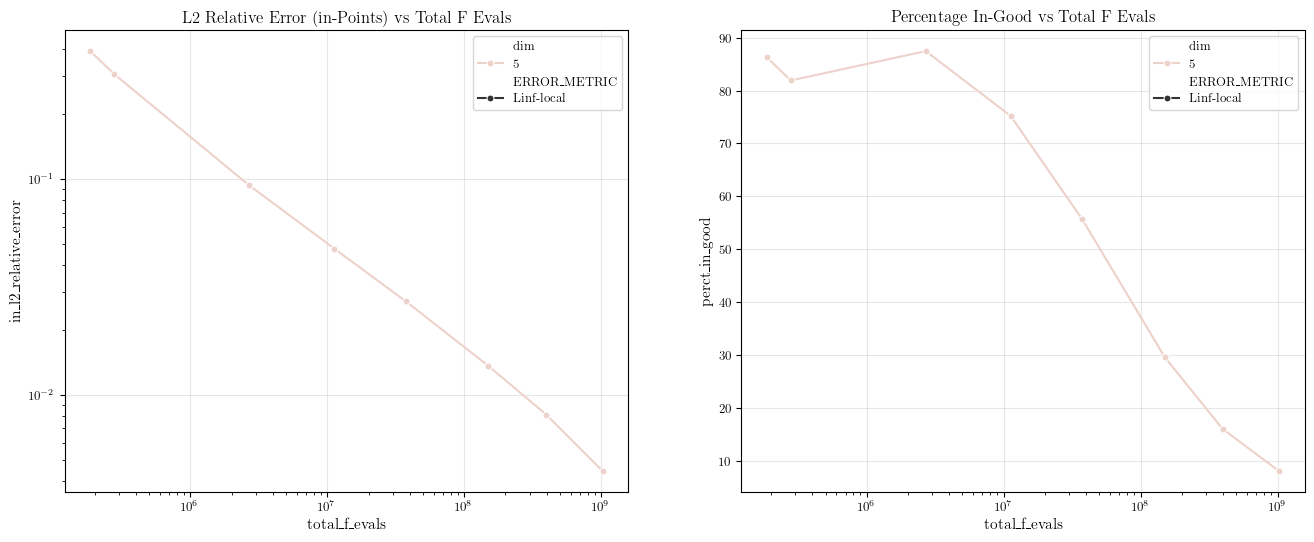

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_problem,
    x="total_f_evals",
    y="in_l2_relative_error",
    hue=dim_col,
    style="ERROR_METRIC",
    marker="o",
)
plt.xscale("log")
plt.yscale("log")
plt.title("L2 Relative Error (in-Points) vs Total F Evals")

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_problem,
    x="total_f_evals",
    y="perct_in_good",
    hue=dim_col,
    style="ERROR_METRIC",
    marker="o",
)
plt.xscale("log")
plt.title("Percentage In-Good vs Total F Evals")

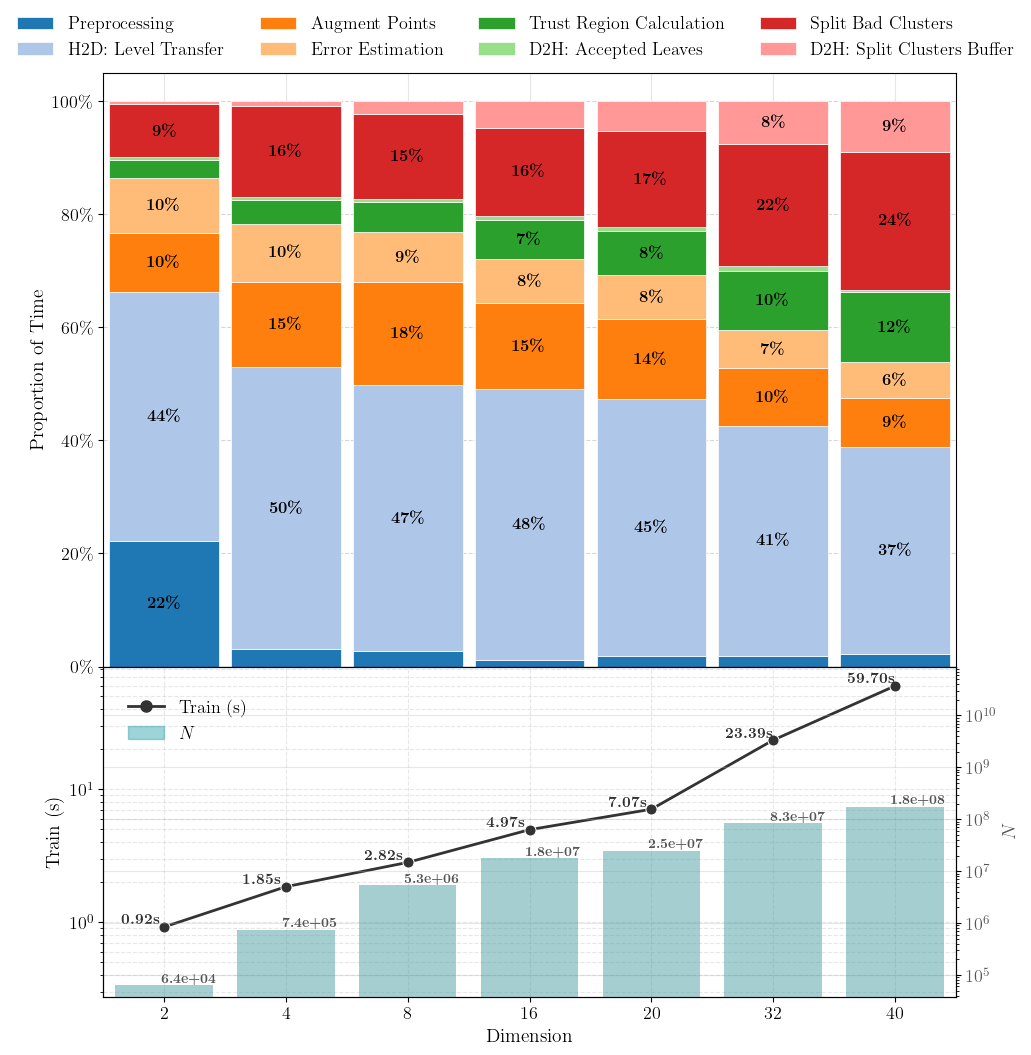

In [ ]:
df_runtime = pd.read_csv(
    ICS26_DIR
    / "ics_anisotropic_quadratic_runtime_scalability"
    / "training_profiles.csv"
)
# drop dim =1
df_runtime = df_runtime[df_runtime["dim"] != 1]
# df_runtime = df_runtime[df_runtime["tol"] == 0.1]
df_runtime = df_runtime.dropna(subset=["time_total"])

# 1. Prepare Data
rename_time_cols = {
    "Preprocessing": ["time_init"],  # Initial F/G eval, Initial K-Means, Sort by labels
    "H2D: Level Transfer": [
        "time_transition",
        "time_slicing",
        "time_gc",
    ],  # Includes CPU concat of all lists, H2D transfer of all np array, deletion time
    "Augment Points": ["time_find_req_synth", "time_synth_gen"],
    "Error Estimation": ["time_error_calc", "time_filter"],
    "Trust Region Calculation": ["time_good_Q"],
    "D2H: Accepted Leaves": ["time_good_d2h"],
    "Split Bad Clusters": ["time_bad_split"],
    "D2H: Split Clusters Buffer": ["time_bad_d2h"],
}

# Create a new DataFrame with aggregated time columns
cleaned_time_df = df_runtime.copy()
for new_col, old_cols in rename_time_cols.items():
    cleaned_time_df[new_col] = cleaned_time_df[old_cols].sum(axis=1)

valid_cols = list(rename_time_cols.keys())
plot_df = cleaned_time_df.set_index("dim")[valid_cols]
plot_df_100 = plot_df.div(plot_df.sum(axis=1), axis=0)

colors = sns.color_palette("tab20", n_colors=len(plot_df_100.columns))

# 2. Setup Figure
# sharex=True aligns the axes. height_ratios gives the bar chart more vertical space.
fig, axs = plt.subplots(
    2, 1, figsize=(11, 12), sharex=True, gridspec_kw={"height_ratios": [1.8, 1]}
)

# --- LAYOUT FIXES ---
# hspace=0 removes gap between plots.
# top=0.88 reserves the top 12% of the figure for Title + Legend
plt.subplots_adjust(hspace=0, top=0.88)

# --- TOP PLOT (Bar) ---
ax_bar = axs[0]
plot_df_100.plot(
    kind="bar",
    stacked=True,
    ax=ax_bar,
    color=colors,
    width=0.9,  # Increased width slightly since gap is gone
    edgecolor="white",
    linewidth=0.5,
    legend=False,
)

# Annotations (Top 5)
TOP_N = 10
ranks = plot_df_100.rank(axis=1, method="min", ascending=False)
for col_idx, container in enumerate(ax_bar.containers):
    for row_idx, patch in enumerate(container):
        rank = int(ranks.iloc[row_idx, col_idx])
        if rank <= TOP_N:
            val = float(plot_df_100.iloc[row_idx, col_idx])
            if val < 0.06:
                continue

            x = patch.get_x() + patch.get_width() / 2
            y = patch.get_y() + patch.get_height() / 2
            ax_bar.text(
                x,
                y,
                rf"\textbf{{{val:.0%}}}".replace("%", r"\%"),
                ha="center",
                va="center",
                color="black",
                fontsize=12,
            )

tick_fontsize = 13
axis_title_fontsize = 14
# Formatting Top Plot
ax_bar.set_ylabel("Proportion of Time", fontsize=axis_title_fontsize)
ax_bar.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax_bar.grid(axis="y", linestyle="--", alpha=0.5)
# Remove x-axis title from the top plot so it doesn't clash with the bottom plot
ax_bar.set_xlabel("")
ax_bar.tick_params(axis="y", labelsize=tick_fontsize)

# --- BOTTOM PLOT (Line) ---
ax_line = axs[1]
x_indices = np.arange(len(df_runtime))
y_values = df_runtime["time_total"].values

sns.lineplot(
    x=x_indices,
    y=y_values,
    marker="o",
    ax=ax_line,
    color="#333333",
    linewidth=2,
    markersize=8,
)

# Annotations for Line Plot
for x, y in zip(x_indices, y_values):
    ax_line.text(
        x - 0.2,
        y,
        rf"\textbf{{{y:.2f}s}}",
        ha="center",
        va="bottom",
        fontsize=11,
        color="#333333",
    )

ax_line.set_ylim(min(y_values) * 0.3, max(y_values) * 1.4)
ax_line.set_yscale("log")
ax_line.set_ylabel("Train (s)", fontsize=axis_title_fontsize)
ax_line.tick_params(axis="x", labelsize=11)
ax_line.set_xlabel("Dimension", fontsize=axis_title_fontsize)
ax_line.grid(True, which="both", linestyle="--", alpha=0.3)
ax_line.set_xticks(x_indices)
ax_line.set_xticklabels(df_runtime["dim"].astype(str))
ax_line.tick_params(axis="y", labelsize=tick_fontsize)
ax_line.tick_params(axis="x", labelsize=tick_fontsize)

# Make secondary y axis to show total_f_evals
bar_color = "#3BABB1"
bar_alpha = 0.5
ax2 = ax_line.twinx()
sns.barplot(
    x=x_indices,
    y=df_runtime["total_f_evals"],
    ax=ax2,
    color=bar_color,
    alpha=bar_alpha,
)
ax2.set_ylabel(r"$N$", color="#555555", fontsize=axis_title_fontsize)
ax2.set_yscale("log")
ax2.tick_params(axis="y", labelcolor="#555555", labelsize=tick_fontsize)
ax2.set_ylim(
    min(df_runtime["total_f_evals"]) * 0.6, max(df_runtime["total_f_evals"]) * 500
)
# Plot data labels for barplot
for x, y in zip(x_indices, df_runtime["total_f_evals"]):
    ax2.text(
        x + 0.2,
        y,
        rf"\textbf{{{y:.1e}}}",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#555555",
    )

# Add custom legend for bottom plot upper left
ax_line.legend(
    handles=[
        Line2D(
            [0],
            [0],
            color="#333333",
            linewidth=2,
            marker="o",
            markersize=8,
            label="Train (s)",
        ),
        mpatches.Patch(color=bar_color, label=r"$N$", alpha=bar_alpha),
    ],
    loc="upper left",
    bbox_to_anchor=(0.01, 0.95),
    frameon=False,
    fontsize=13,
)
# --- HEADER (Title & Legend) ---
# 1. Main Figure Title (Highest)
# fig.suptitle(r"\textbf{Time Breakdown by Dimension}", fontsize=16, y=0.98)

# 2. Legend (Between Title and Plot)
handles, labels = ax_bar.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=4,
    frameon=False,
    fontsize=13,
)

plt.savefig(
    "ics26_quadratic_runtime_breakdown_vs_dimension.svg",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1,
)

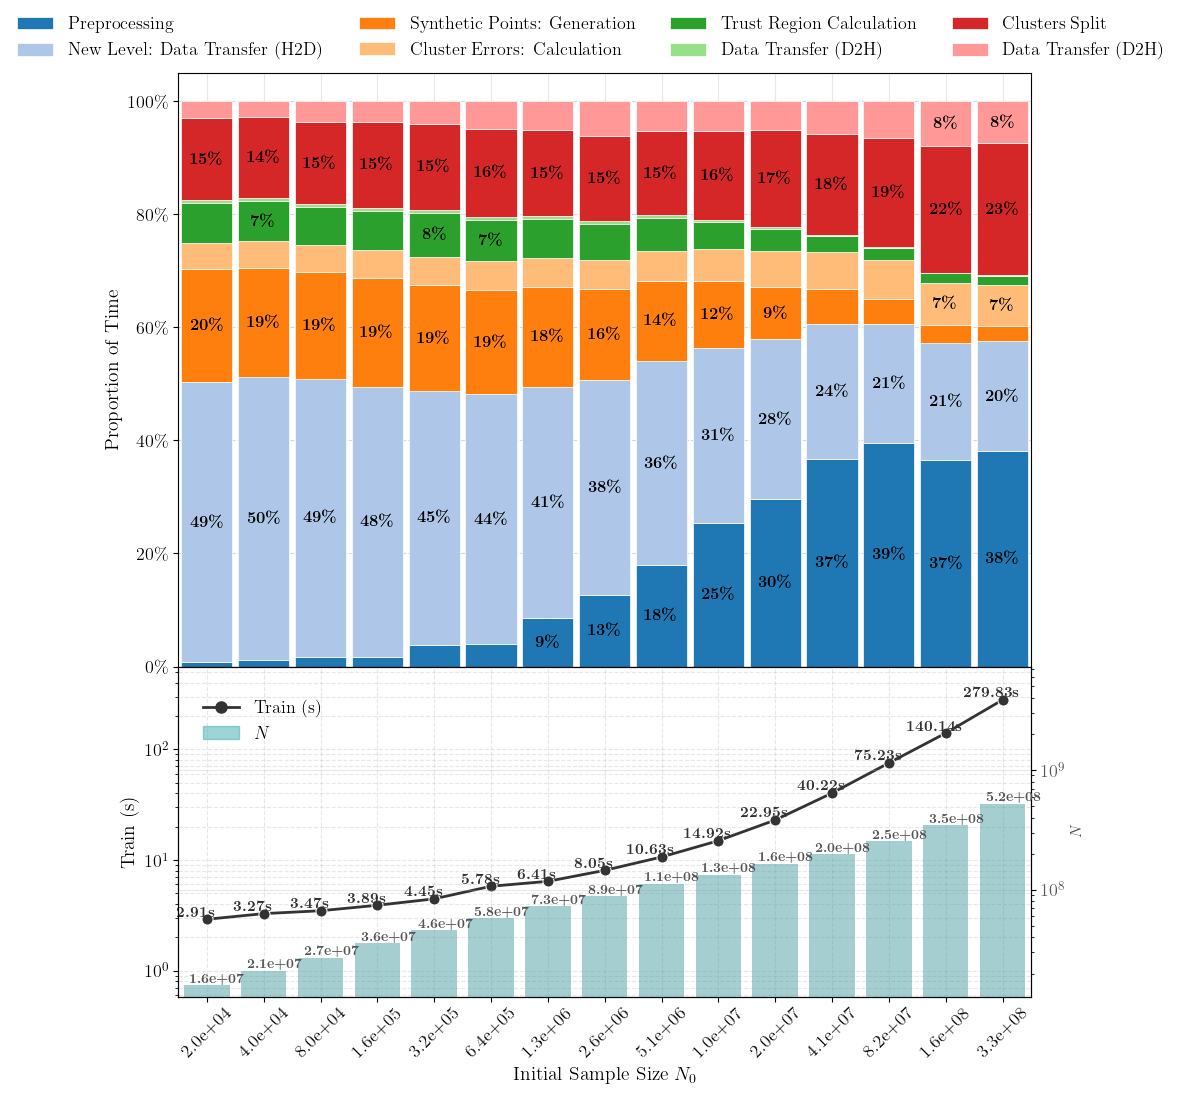

In [ ]:
df_runtime = pd.read_csv(
    ICS26_DIR / "ics_rosenbrock_runtime_scalability_n0" / "training_profiles.csv"
)
df_runtime = df_runtime.sort_values(by="N0")
df_runtime = df_runtime[df_runtime["dim"] != 1]
df_runtime = df_runtime[df_runtime["N0"] >= 20_000]
df_runtime = df_runtime.dropna(subset=["time_total"])

# 1. Prepare Data
rename_time_cols = {
    "Preprocessing": ["time_init"],  # Initial F/G eval, Initial K-Means, Sort by labels
    "New Level: Data Transfer (H2D)": [
        "time_transition",
        "time_slicing",
        "time_gc",
    ],  # Includes CPU concat of all lists, H2D transfer of all np array, deletion time
    "Synthetic Points: Generation": ["time_find_req_synth", "time_synth_gen"],
    "Cluster Errors: Calculation": ["time_error_calc", "time_filter"],
    "Trust Region Calculation": ["time_good_Q"],
    "D2H: Accepted Leaves": ["time_good_d2h"],
    "Clusters Split": ["time_bad_split"],
    "D2H: Split Clusters Buffer": ["time_bad_d2h"],
}

# Create a new DataFrame with aggregated time columns
# drop N0 = 10,000
cleaned_time_df = df_runtime.copy()
for new_col, old_cols in rename_time_cols.items():
    cleaned_time_df[new_col] = cleaned_time_df[old_cols].sum(axis=1)

valid_cols = list(rename_time_cols.keys())
plot_df = cleaned_time_df.set_index("N0")[valid_cols]
plot_df_100 = plot_df.div(plot_df.sum(axis=1), axis=0)

colors = sns.color_palette("tab20", n_colors=len(plot_df_100.columns))

# 2. Setup Figure
# sharex=True aligns the axes. height_ratios gives the bar chart more vertical space.
fig, axs = plt.subplots(
    2, 1, figsize=(11, 12), sharex=True, gridspec_kw={"height_ratios": [1.8, 1]}
)

# --- LAYOUT FIXES ---
# hspace=0 removes gap between plots.
# top=0.88 reserves the top 12% of the figure for Title + Legend
plt.subplots_adjust(hspace=0, top=0.88)

# --- TOP PLOT (Bar) ---
ax_bar = axs[0]
plot_df_100.plot(
    kind="bar",
    stacked=True,
    ax=ax_bar,
    color=colors,
    width=0.9,  # Increased width slightly since gap is gone
    edgecolor="white",
    linewidth=0.5,
    legend=False,
)

# Annotations (Top 5)
TOP_N = 10
ranks = plot_df_100.rank(axis=1, method="min", ascending=False)
for col_idx, container in enumerate(ax_bar.containers):
    for row_idx, patch in enumerate(container):
        rank = int(ranks.iloc[row_idx, col_idx])
        if rank <= TOP_N:
            val = float(plot_df_100.iloc[row_idx, col_idx])
            if val < 0.07:
                continue

            x = patch.get_x() + patch.get_width() / 2
            y = patch.get_y() + patch.get_height() / 2
            ax_bar.text(
                x,
                y,
                rf"\textbf{{{val:.0%}}}".replace("%", r"\%"),
                ha="center",
                va="center",
                color="black",
                fontsize=12,
            )

tick_fontsize = 13
axis_title_fontsize = 14
# Formatting Top Plot
ax_bar.set_ylabel("Proportion of Time", fontsize=axis_title_fontsize)
ax_bar.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax_bar.grid(axis="y", linestyle="--", alpha=0.5)
# Remove x-axis title from the top plot so it doesn't clash with the bottom plot
ax_bar.set_xlabel("")
ax_bar.tick_params(axis="y", labelsize=tick_fontsize)

# --- BOTTOM PLOT (Line) ---
ax_line = axs[1]
x_indices = np.arange(len(df_runtime))
y_values = df_runtime["time_total"].values

sns.lineplot(
    x=x_indices,
    y=y_values,
    marker="o",
    ax=ax_line,
    color="#333333",
    linewidth=2,
    markersize=8,
)

# Annotations for Line Plot
for x, y in zip(x_indices, y_values):
    ax_line.text(
        x - 0.2,
        y,
        rf"\textbf{{{y:.2f}s}}",
        ha="center",
        va="bottom",
        fontsize=11,
        color="#333333",
    )


ax_line.set_ylim(min(y_values) * 0.2, max(y_values) * 2)
ax_line.set_yscale("log")
ax_line.set_ylabel("Train (s)", fontsize=axis_title_fontsize)
ax_line.tick_params(axis="x", labelsize=11)
ax_line.grid(True, which="both", linestyle="--", alpha=0.3)
ax_line.set_xticks(x_indices)
ax_line.set_xticklabels(
    [f"{int(val):.1e}" for val in df_runtime["N0"].values], rotation=45
)
ax_line.set_xlabel("Initial Sample Size $N_0$", fontsize=axis_title_fontsize)
ax_line.tick_params(axis="x", labelsize=tick_fontsize)
ax_line.tick_params(axis="y", labelsize=tick_fontsize)

# Make secondary y axis to show num_levels
bar_color = "#3BABB1"
bar_alpha = 0.5
ax2 = ax_line.twinx()
col_to_plot = "total_f_evals"
sns.barplot(
    x=x_indices,
    y=df_runtime[col_to_plot],
    ax=ax2,
    color=bar_color,
    alpha=bar_alpha,
)
ax2.set_ylabel(r"$N$", color="#555555")
ax2.set_yscale("log")
ax2.tick_params(axis="y", labelcolor="#555555")
ax2.set_ylim(min(df_runtime[col_to_plot]) * 0.8, max(df_runtime[col_to_plot]) * 14)
ax2_line = ax2.get_yticks()
ax2.tick_params(axis="y", labelsize=tick_fontsize)

# Plot data labels for barplot
for x, y in zip(x_indices, df_runtime[col_to_plot]):
    ax2.text(
        x + 0.2,
        y,
        rf"\textbf{{{y:.1e}}}",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#555555",
    )

# Add custom legend for bottom plot upper left
ax_line.legend(
    handles=[
        Line2D(
            [0],
            [0],
            color="#333333",
            linewidth=2,
            marker="o",
            markersize=8,
            label="Train (s)",
        ),
        mpatches.Patch(color=bar_color, label=r"$N$", alpha=bar_alpha),
    ],
    loc="upper left",
    bbox_to_anchor=(0.01, 0.95),
    frameon=False,
    fontsize=13,
)


# --- HEADER (Title & Legend) ---
# 1. Main Figure Title (Highest)
# fig.suptitle(r"\textbf{Time Breakdown by Dimension}", fontsize=16, y=0.98)

# 2. Legend (Between Title and Plot)
handles, labels = ax_bar.get_legend_handles_labels()
for i, label in enumerate(labels):
    if "D2H" in label:
        labels[i] = "Data Transfer (D2H)"

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=4,
    frameon=False,
    fontsize=13,
)

plt.savefig(
    "ics26_rosenbrock_runtime_breakdown_vs_initial_sample_size.svg",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1,
)

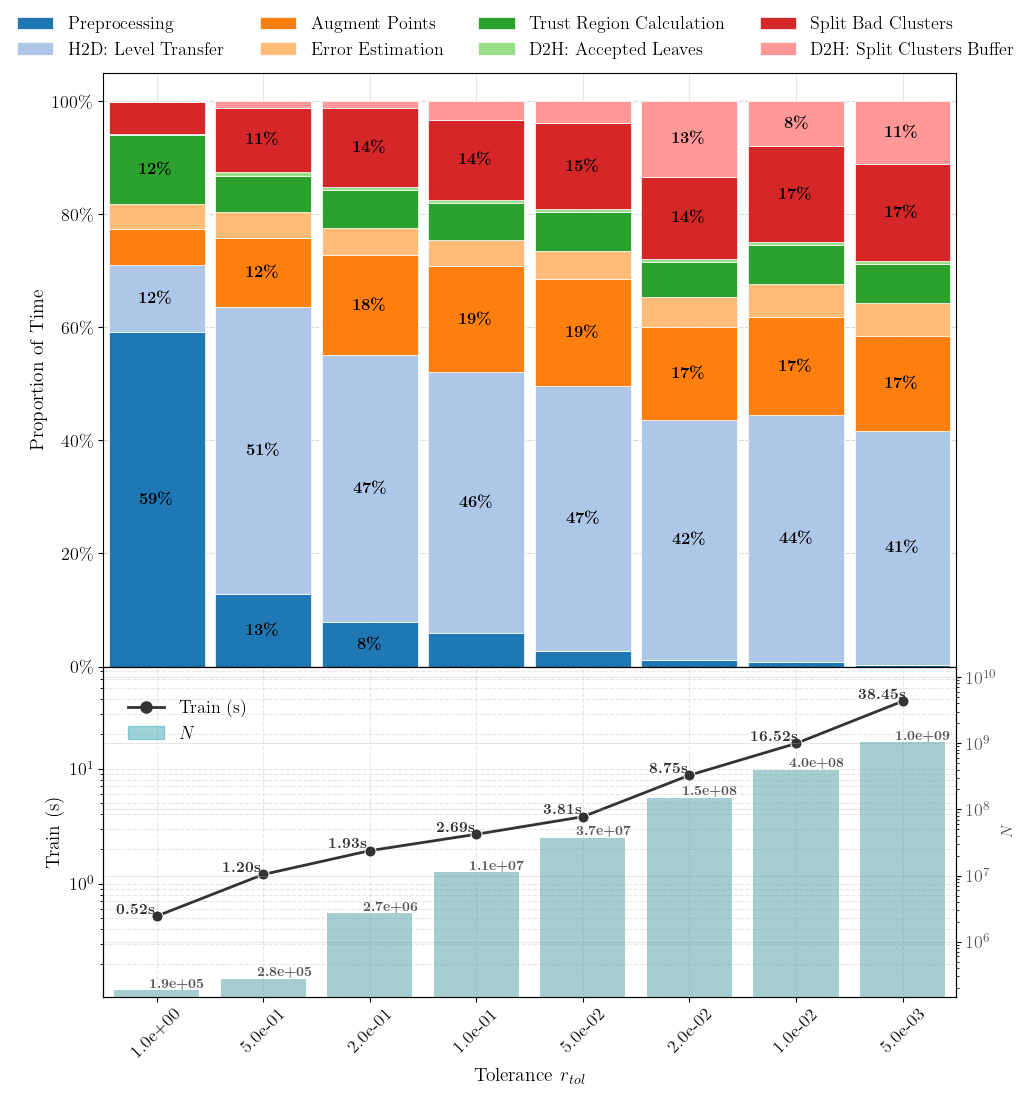

In [ ]:
df_runtime = pd.read_csv(
    ICS26_DIR / "ics_rosenbrock_runtime_scalability" / "training_profiles.csv"
)
df_runtime = df_runtime.sort_values(by="N0")
df_runtime = df_runtime[df_runtime["dim"] != 1]
df_runtime = df_runtime[df_runtime["N0"] >= 20_000]
df_runtime = df_runtime.dropna(subset=["time_total"])

# 1. Prepare Data
rename_time_cols = {
    "Preprocessing": ["time_init"],  # Initial F/G eval, Initial K-Means, Sort by labels
    "H2D: Level Transfer": [
        "time_transition",
        "time_slicing",
        "time_gc",
    ],  # Includes CPU concat of all lists, H2D transfer of all np array, deletion time
    "Augment Points": ["time_find_req_synth", "time_synth_gen"],
    "Error Estimation": ["time_error_calc", "time_filter"],
    "Trust Region Calculation": ["time_good_Q"],
    "D2H: Accepted Leaves": ["time_good_d2h"],
    "Split Bad Clusters": ["time_bad_split"],
    "D2H: Split Clusters Buffer": ["time_bad_d2h"],
}

# Create a new DataFrame with aggregated time columns
cleaned_time_df = df_runtime.copy()
for new_col, old_cols in rename_time_cols.items():
    cleaned_time_df[new_col] = cleaned_time_df[old_cols].sum(axis=1)

valid_cols = list(rename_time_cols.keys())
plot_df = cleaned_time_df.set_index("tol")[valid_cols]
plot_df_100 = plot_df.div(plot_df.sum(axis=1), axis=0)

colors = sns.color_palette("tab20", n_colors=len(plot_df_100.columns))

# 2. Setup Figure
# sharex=True aligns the axes. height_ratios gives the bar chart more vertical space.
fig, axs = plt.subplots(
    2, 1, figsize=(11, 12), sharex=True, gridspec_kw={"height_ratios": [1.8, 1]}
)

# --- LAYOUT FIXES ---
# hspace=0 removes gap between plots.
# top=0.88 reserves the top 12% of the figure for Title + Legend
plt.subplots_adjust(hspace=0, top=0.88)

# --- TOP PLOT (Bar) ---
ax_bar = axs[0]
plot_df_100.plot(
    kind="bar",
    stacked=True,
    ax=ax_bar,
    color=colors,
    width=0.9,  # Increased width slightly since gap is gone
    edgecolor="white",
    linewidth=0.5,
    legend=False,
)

# Annotations (Top 5)
TOP_N = 10
ranks = plot_df_100.rank(axis=1, method="min", ascending=False)
for col_idx, container in enumerate(ax_bar.containers):
    for row_idx, patch in enumerate(container):
        rank = int(ranks.iloc[row_idx, col_idx])
        if rank <= TOP_N:
            val = float(plot_df_100.iloc[row_idx, col_idx])
            if val < 0.07:
                continue

            x = patch.get_x() + patch.get_width() / 2
            y = patch.get_y() + patch.get_height() / 2
            ax_bar.text(
                x,
                y,
                rf"\textbf{{{val:.0%}}}".replace("%", r"\%"),
                ha="center",
                va="center",
                color="black",
                fontsize=12,
            )

tick_fontsize = 13
axis_title_fontsize = 14
# Formatting Top Plot
ax_bar.set_ylabel("Proportion of Time", fontsize=axis_title_fontsize)
ax_bar.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax_bar.grid(axis="y", linestyle="--", alpha=0.5)
# Remove x-axis title from the top plot so it doesn't clash with the bottom plot
ax_bar.set_xlabel("")
ax_bar.tick_params(axis="y", labelsize=tick_fontsize)

# --- BOTTOM PLOT (Line) ---
ax_line = axs[1]
x_indices = np.arange(len(df_runtime))
y_values = df_runtime["time_total"].values

sns.lineplot(
    x=x_indices,
    y=y_values,
    marker="o",
    ax=ax_line,
    color="#333333",
    linewidth=2,
    markersize=8,
)

# Annotations for Line Plot
for x, y in zip(x_indices, y_values):
    ax_line.text(
        x - 0.2,
        y,
        rf"\textbf{{{y:.2f}s}}",
        ha="center",
        va="bottom",
        fontsize=11,
        color="#333333",
    )


ax_line.set_ylim(min(y_values) * 0.2, max(y_values) * 2)
ax_line.set_yscale("log")
ax_line.set_ylabel("Train (s)", fontsize=axis_title_fontsize)
ax_line.tick_params(axis="x", labelsize=11)
ax_line.grid(True, which="both", linestyle="--", alpha=0.3)
ax_line.set_xticks(x_indices)
ax_line.set_xticklabels([f"{val:.1e}" for val in df_runtime["tol"].values], rotation=45)
ax_line.set_xlabel("Tolerance $r_{tol}$", fontsize=axis_title_fontsize)
ax_line.tick_params(axis="x", labelsize=tick_fontsize)
ax_line.tick_params(axis="y", labelsize=tick_fontsize)

# Make secondary y axis to show num_levels
bar_color = "#3BABB1"
bar_alpha = 0.5
ax2 = ax_line.twinx()
col_to_plot = "total_f_evals"
sns.barplot(
    x=x_indices,
    y=df_runtime[col_to_plot],
    ax=ax2,
    color=bar_color,
    alpha=bar_alpha,
)
ax2.set_ylabel(r"$N$", color="#555555")
ax2.set_yscale("log")
ax2.tick_params(axis="y", labelcolor="#555555")
ax2.set_ylim(min(df_runtime[col_to_plot]) * 0.8, max(df_runtime[col_to_plot]) * 14)
ax2_line = ax2.get_yticks()
ax2.tick_params(axis="y", labelsize=tick_fontsize)

# Plot data labels for barplot
for x, y in zip(x_indices, df_runtime[col_to_plot]):
    ax2.text(
        x + 0.2,
        y,
        rf"\textbf{{{y:.1e}}}",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#555555",
    )

# Add custom legend for bottom plot upper left
ax_line.legend(
    handles=[
        Line2D(
            [0],
            [0],
            color="#333333",
            linewidth=2,
            marker="o",
            markersize=8,
            label="Train (s)",
        ),
        mpatches.Patch(color=bar_color, label=r"$N$", alpha=bar_alpha),
    ],
    loc="upper left",
    bbox_to_anchor=(0.01, 0.95),
    frameon=False,
    fontsize=13,
)


# --- HEADER (Title & Legend) ---
# 1. Main Figure Title (Highest)
# fig.suptitle(r"\textbf{Time Breakdown by Dimension}", fontsize=16, y=0.98)

# 2. Legend (Between Title and Plot)
handles, labels = ax_bar.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=4,
    frameon=False,
    fontsize=13,
)

plt.savefig(
    "ics26_rosenbrock_runtime_breakdown_vs_tolerance.svg",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1,
)

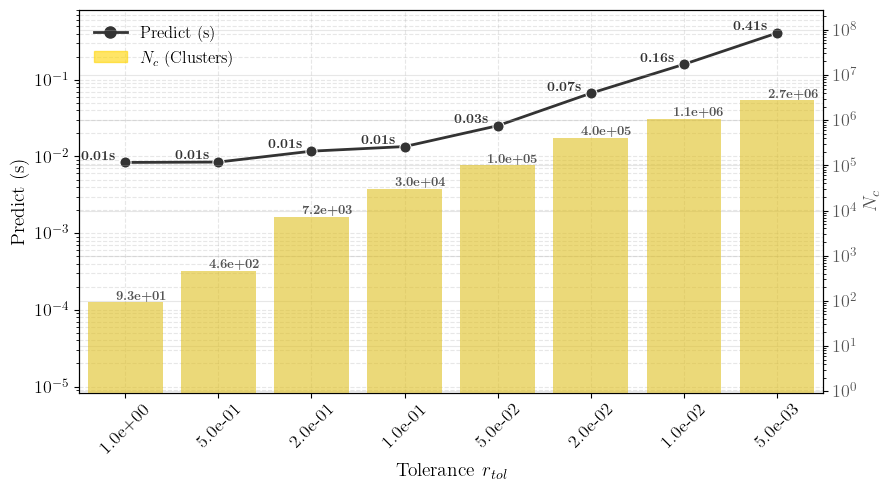

In [ ]:
# --- FINAL PLOT: Predict Time Scalability ---
df_runtime = pd.read_csv(
    ICS26_DIR / "ics_rosenbrock_runtime_scalability" / "summary.csv"
)
# tolerance descending (standard for these plots)
df_runtime = df_runtime.sort_values(by="tol", ascending=False)
df_runtime = df_runtime.dropna(subset=["n_clusters"])

fig, ax_line = plt.subplots(figsize=(9, 5))

# Use categorical indices for even bar spacing
x_indices = np.arange(len(df_runtime))
y_time = df_runtime["predict_time_sec"].values
y_clusters = df_runtime["n_clusters"].values

# 1. Plot Predict Time (Line)
sns.lineplot(
    x=x_indices,
    y=y_time,
    marker="o",
    ax=ax_line,
    color="#333333",
    linewidth=2,
    markersize=8,
)

# Annotations for Line Plot
for x, y in zip(x_indices, y_time):
    ax_line.text(
        x - 0.1,
        y,
        rf"\textbf{{{y:.2f}s}}",
        ha="right",
        va="bottom",
        fontsize=10,
        color="#333333",
    )

# Formatting Primary Axis
ax_line.set_yscale("log")
ax_line.set_ylabel("Predict (s)", fontsize=axis_title_fontsize)
ax_line.set_xlabel(r"Tolerance $r_{tol}$", fontsize=axis_title_fontsize)
ax_line.set_ylim(min(y_time) * 0.001, max(y_time) * 2)
ax_line.set_xticks(x_indices)
ax_line.set_xticklabels([f"{val:.1e}" for val in df_runtime["tol"].values], rotation=45)
ax_line.tick_params(axis="both", labelsize=tick_fontsize)
ax_line.grid(True, which="both", linestyle="--", alpha=0.3)

# 2. Plot Number of Clusters (Secondary Y-Axis Bars)
bar_color = "#FFD500"
bar_alpha = 0.6
ax2 = ax_line.twinx()
sns.barplot(
    x=x_indices,
    y=y_clusters,
    ax=ax2,
    color=bar_color,
    alpha=bar_alpha,
)

# Annotations for Bars
for x, y in zip(x_indices, y_clusters):
    ax2.text(
        x - 0.1,
        y,
        rf"\textbf{{{y:.1e}}}",
        ha="left",
        va="bottom",
        fontsize=9,
        color="#555555",
    )

# Formatting Secondary Axis
ax2.set_yscale("log")
ax2.set_ylabel(r"$N_c$", color="#555555", fontsize=axis_title_fontsize)
ax2.tick_params(axis="y", labelcolor="#555555", labelsize=tick_fontsize)
# Set limits to leave room for text at the top
ax2.set_ylim(min(y_clusters) * 0.01, max(y_clusters) * 100)

# 3. Custom Legend
ax_line.legend(
    handles=[
        Line2D(
            [0],
            [0],
            color="#333333",
            linewidth=2,
            marker="o",
            markersize=8,
            label="Predict (s)",
        ),
        mpatches.Patch(color=bar_color, label=r"$N_c$ (Clusters)", alpha=bar_alpha),
    ],
    loc="upper left",
    frameon=False,
    fontsize=12,
)

plt.tight_layout()
plt.savefig(
    "ics26_rosenbrock_predict_scalability_vs_tolerance.svg",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

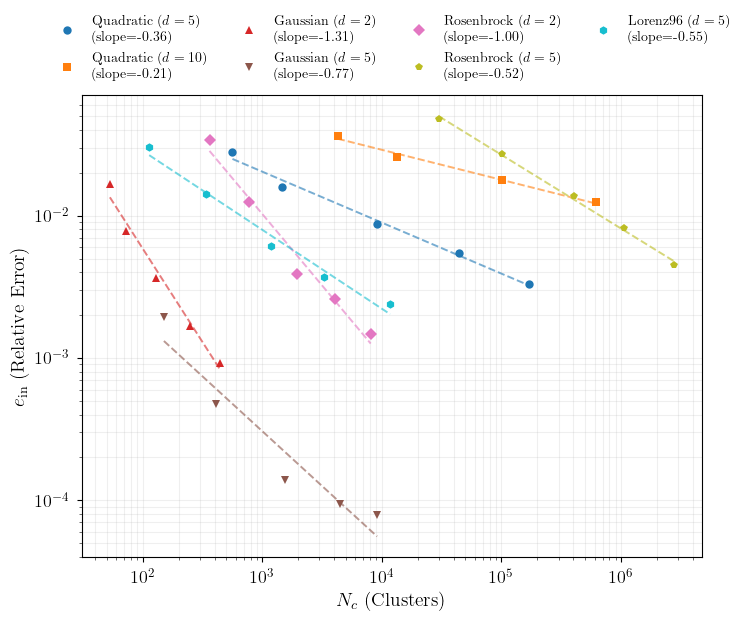

In [53]:
from scipy.stats import linregress

# Quadratic (d=5)
Nc_quad_d5 = np.array([562, 1460, 9157, 43_805, 168_418])
ein_quad_d5 = np.array([2.82e-02, 1.58e-02, 8.71e-03, 5.46e-03, 3.31e-03])

# Quadratic (d=10)
Nc_quad_d10 = np.array([4266, 13_290, 100_616, 613_701])
ein_quad_d10 = np.array([3.63e-02, 2.59e-02, 1.77e-02, 1.24e-02])

# Gaussian (d=2)
Nc_gauss_d2 = np.array([53, 72, 130, 246, 446])
ein_gauss_d2 = np.array([1.66e-02, 7.82e-03, 3.66e-03, 1.69e-03, 9.22e-04])

# Gaussian (d=5)
Nc_gauss_d5 = np.array([150, 407, 1540, 4462, 9109])
ein_gauss_d5 = np.array([1.95e-03, 4.75e-04, 1.38e-04, 9.42e-05, 7.84e-05])

# Rosenbrock (d=2)
Nc_rosen_d2 = np.array([361, 776, 1962, 4063, 8051])
ein_rosen_d2 = np.array([3.38e-02, 1.25e-02, 3.89e-03, 2.58e-03, 1.47e-03])

# Rosenbrock (d=5)
Nc_rosen_d5 = np.array([30_110, 100_396, 401_212, 1_064_029, 2_749_440])
ein_rosen_d5 = np.array([4.79e-02, 2.71e-02, 1.37e-02, 8.14e-03, 4.53e-03])

# Lorenz96 (d=5)
Nc_lorenz_d5 = np.array([113, 337, 1188, 3281, 11_717])
ein_lorenz_d5 = np.array([3.05e-02, 1.41e-02, 6.10e-03, 3.69e-03, 2.41e-03])


# Data extraction (using the provided arrays)
data = {
    "Quadratic ($d=5$)": (Nc_quad_d5, ein_quad_d5),
    "Quadratic ($d=10$)": (Nc_quad_d10, ein_quad_d10),
    "Gaussian ($d=2$)": (Nc_gauss_d2, ein_gauss_d2),
    "Gaussian ($d=5$)": (Nc_gauss_d5, ein_gauss_d5),
    "Rosenbrock ($d=2$)": (Nc_rosen_d2, ein_rosen_d2),
    "Rosenbrock ($d=5$)": (Nc_rosen_d5, ein_rosen_d5),
    "Lorenz96 ($d=5$)": (Nc_lorenz_d5, ein_lorenz_d5),
}

# Publishing-ready styles
plt.style.use("seaborn-v0_8-paper")
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 11,
        "axes.labelsize": 12,
        "legend.fontsize": 9,  # Adjusted slightly for horizontal fit
        "lines.markersize": 6,
    }
)

fig, ax = plt.subplots(figsize=(8, 6))
colors = plt.cm.tab10(np.linspace(0, 1, len(data)))
markers = ["o", "s", "^", "v", "D", "p", "h"]

for i, (name, (Nc, ein)) in enumerate(data.items()):
    log_Nc = np.log10(Nc)
    log_ein = np.log10(ein)
    slope, intercept, _, _, _ = linregress(log_Nc, log_ein)

    # Plot data points
    ax.loglog(
        Nc,
        ein,
        marker=markers[i],
        linestyle="None",
        color=colors[i],
        label=f"{name}\n(slope={slope:.2f})",
    )

    # Plot linear fit
    fit_line = 10 ** (intercept + slope * log_Nc)
    ax.loglog(Nc, fit_line, linestyle="--", color=colors[i], alpha=0.6)

# Formatting
ax.set_xlabel(r"$N_c$ (Clusters)", fontsize=axis_title_fontsize)
ax.set_ylabel(r"$e_{\mathrm{in}}$ (Relative Error)", fontsize=axis_title_fontsize)
ax.tick_params(axis="both", labelsize=tick_fontsize)

ax.grid(True, which="both", ls="-", alpha=0.2)

# Positioning the legend on top with 4 columns
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.2),
    ncol=4,
    frameon=False,
    fancybox=False,
    fontsize=10,
)

plt.savefig("convergence_plot.png", dpi=300, bbox_inches="tight")